# Redes neuronales convolucionales
## Introducción a la Ciencia de datos
## Licenciatura en Ciencias Genómicas

### Dr. Carlos Francisco Méndez Cruz

Notebook adaptado de la [Capacitación oficial de PyTorch.](https://pytorch.org/tutorials/beginner/basics/quickstart_tutorial.html)

------------------------------------------------------------------------


## Objetivo de la práctica

Entrenar una Red Neuronal Convolucional (_Convolutional Neural Network_, CNN) para predecir el tipo de vestimenta usando imágenes en blanco y negro.

## Descripción de la tarea
El modelo debe clasificar imágenes en blanco y negro en 10 posibles tipos de vestimenta:

0. T-shirt/top (Camiseta/top)
1. Trouser (Pantalón)
2. Pullover (Jersey)
3. Dress (Vestido)
4. Coat (Abrigo)
5. Sandal (Sandalia)
6. Shirt (Camisa)
7. Sneaker (Zapato deportivo)
8. Bag (Bolso)
9. Ankle boot (Botín)

## Conjunto de datos
Usaremos el conjunto de datos llamado [Fashion MNIST](https://en.wikipedia.org/wiki/Fashion_MNIST).

![Fashion MNIST](https://github.com/zalandoresearch/fashion-mnist/raw/master/doc/img/fashion-mnist-sprite.png)

------------------------------------------------------------------------


## Importación de librerías

In [1]:
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

import torch.nn.functional as F
import torchvision
from torchvision import datasets
from torchvision.transforms import ToTensor

import numpy as np
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, classification_report
import matplotlib.pyplot as plt



# Manejo de datos

## 1. Descarga de conjuntos de entrenamiento y prueba

El módulo `torchvision.datasets` contiene diversos conjuntos de datos disponibles para uso libre y precargados en PyTorch, especialmente de imágenes. Estos conjuntos de datos están disponibles como objetos de la clase `Dataset`. Para esta práctica descargaremos el conjunto de datos `Fashion MNIST (datasets.FashionMNIS)`.

* El argumento `train` permite indicar si queremos los datos de entrenamiento `train=True` o los datos de prueba `train=False`.
* El argumento `download=True` permite indicar si el dataset debe ser descargado en nuestro disco o Drive.
* El argumento `transform` permite indicar una transformación de los datos, en este caso los datos son transformados en tensores con la función ToTensor().

Con las siguientes instrucciones tendremos dos PyTorch DataSets: uno para entrenamiento (`dataset_train`) y el otro para prueba (`dataset_test`).

In [2]:
dataset_train = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=ToTensor(),
)

# Download test data from open datasets.
dataset_test = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=ToTensor(),
)

## 2. De PyTorch DataSet a PyTorch DataLoader

Para definir el DataLoader, necesitamos establecer un tamaño de lote (batch_size). La red neuronal ajustará sus pesos cada lote.

In [3]:
batch_size = 64

dataloader_train = DataLoader(dataset_train, batch_size=batch_size)
dataloader_test = DataLoader(dataset_test, batch_size=batch_size, shuffle=False)

### Observar dimensionalidad del DataLoader

In [4]:
for X, y in dataloader_train:
    print("Dimensionalidad de datos del primer lote del DataLoader de entrenamiento:", X.shape)
    print("Dimensionalidad de categorías del primer lote del DataLoader de entrenamiento:", y.shape)
    print("Ids de categorías del primer lote del DataLoader de entrenamiento:", y)
    break

Dimensionalidad de datos del primer lote del DataLoader de entrenamiento: torch.Size([64, 1, 28, 28])
Dimensionalidad de categorías del primer lote del DataLoader de entrenamiento: torch.Size([64])
Ids de categorías del primer lote del DataLoader de entrenamiento: tensor([9, 0, 0, 3, 0, 2, 7, 2, 5, 5, 0, 9, 5, 5, 7, 9, 1, 0, 6, 4, 3, 1, 4, 8,
        4, 3, 0, 2, 4, 4, 5, 3, 6, 6, 0, 8, 5, 2, 1, 6, 6, 7, 9, 5, 9, 2, 7, 3,
        0, 3, 3, 3, 7, 2, 2, 6, 6, 8, 3, 3, 5, 0, 5, 5])


### Diccionario para convertir ids en categorías


In [5]:
ids_en_categorias = {
    0: "Camiseta/top",
    1: "Pantalón",
    2: "Jersey",
    3: "Vestido",
    4: "Abrigo",
    5: "Sandalia",
    6: "Camisa",
    7: "Zapato deportivo",
    8: "Bolso",
    9: "Botín"
}

In [7]:
print(ids_en_categorias[7])

Zapato deportivo


# Definición de `device` para entrenamiento

In [8]:
if torch.cuda.is_available():
  device = "cuda"
else:
  device = "cpu"

print("Device disponible para entrenamiento:", device)

Device disponible para entrenamiento: cuda


# Diseño de la arquitectura de la red neuronal

### Definición de arquitectura de la red neuronal

Creamos nuestra clase `CNN` a partir de la clase base de PyTorch [nn.Module](https://pytorch.org/docs/stable/generated/torch.nn.Module.html). Nuestra clase será definida de acuerdo a la arquitectura de red que deseamos entrenar.

Para una Red Neuronal Convolucional debemos definir:
- Capas convolucionales
- Capas de función de activación
- Capas de pooling
- Capa totalmente conectada
- Procesamiento hacia adelante de la red (`forward`)


In [16]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        # Primera capa convolucional. 1 canal de entrada, 32 canales de salida, filtro 3x3
        self.conv1 = nn.Conv2d(1, 32, 3)
        # Segunda capa convolucional. 32 canales de entrada, 64 canales de salida, filtro 3x3
        self.conv2 = nn.Conv2d(32, 64, 3)
        # Red totalmente conectada:
        #   Primera capa totalmente conectada. Entrada con 64*5*5 neuronas del aplanado de matrices. Salida con 128 neuronas.
        self.fc1 = nn.Linear(64 * 5 * 5, 128)
        #   Segunda capa totalmente conectada. Entrada con 128 neuronas. Salida con 10 neuronas.
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        # Input: [batch_size, 1, 28, 28]
        x = F.relu(self.conv1(x))
        # Shape: [batch_size, 32, 26, 26]
        x = F.max_pool2d(x, 2)
        # Shape: [batch_size, 32, 13, 13]

        x = F.relu(self.conv2(x))
        # Shape: [batch_size, 64, 11, 11]
        x = F.max_pool2d(x, 2)
        # Shape: [batch_size, 64, 5, 5]

        x = x.view(-1, 64 * 5 * 5) # Aplanado
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

## Creación de red neuronal en `device`
Usando la clase definida anteriormente, creamos nuestra red neuronal e indicamos que la red será entrenada en el `device` definido anteriormente.

In [37]:
red_cnn = CNN().to(device)
print(red_cnn)

CNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
  (fc1): Linear(in_features=1600, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


## Definición de función de pérdida, optimizador y tasa de aprendizaje

La [función de pérdida (loss function)](https://pytorch.org/docs/stable/nn.html#loss-functions) más recomendada para resolver tareas de clasificación multiclase es la Entropía cruzada (`CrossEntropyLoss`).

Utilizaremos un [optimizador](https://pytorch.org/docs/stable/optim.html) adaptativo (`Adam`).

La tasa de aprendizaje (learning rate o `lr`) será definida como 0.001 (`1e-3`).

In [38]:
funcion_de_perdida = nn.CrossEntropyLoss()
optimizador_de_pesos = torch.optim.Adam(red_cnn.parameters(), lr=0.001)

# Entrenamiento y evaluación de la red neuronal

## Definición de función de entrenamiento (`train`)

Esto incluye procesar las imágenes del `DataLoader` lote por lote "hacia delante" y calcular el valor de la función de pérdida. Luego ejecutaremos el paso "hacia atrás" o backpropagation para calcular los gradientes. Finalmente ejecutaremos el ajuste de los pesos de la red. En cada iteración, la red deberá predecir cada vez mejor.


In [39]:
def train(dataloader, red, funcion_perdida, optimizador):
    total_de_registros = len(dataloader.dataset)
    # Activamos nuestra red en modo de entrenamiento
    red.train()

    # Para cada batch, datos y categorías:
    for lote, (X, y) in enumerate(dataloader):
        # Enviamos datos y categorías al device
        X, y = X.to(device), y.to(device)
        # Obtenemos predicciones de la red (logits) para el conjunto de datos del lote (forward)
        logits = red(X)
        valor_de_perdida = funcion_perdida(logits, y)
        # Backpropagation
        valor_de_perdida.backward()
        # Modificación (ajuste) de pesos
        optimizador.step()
        # Reseteo de gradientes para evitar acumulación
        optimizador.zero_grad()

        # Cada 100 batches
        if lote % 100 == 0:
            print("Lote número:", lote)
            # Calculamos registros procesados multiplicando el número de lote (`lote`) por la cantidad de registros del lote (`X`)
            registros_procesados = (lote + 1) * len(X)
            # item() regresa el valor del tensor en tipo numérico de Python
            print("Valor de función de pérdida:", valor_de_perdida.item(), "Lote:", lote, "Registros:[", registros_procesados, "/", total_de_registros, "]")


## Definición de función de prueba (`test`)

Esto incluye procesar los datos de prueba lote por lote con la red previamente entrenada. Para cada lote se calculará el valor de la función de perdida y el procentaje de aciertos de las predicciones de la red (`Accuracy`).


In [40]:
def test(dataloader, red, funcion_perdida):
    total_de_registros = len(dataloader.dataset)
    # Obtenemos el número de lotes de los datos de prueba
    numero_de_lotes = len(dataloader)
    # Activamos nuestra red en modo de prueba
    red.eval()

    # Inicializamos valor de función de pérdida y número de predicciones correctas
    valor_de_perdida_acumulado = 0
    predicciones_correctas_acumuladas = 0

    # Creamos listas para juntar las categorías predichas y las categorías verdaderas
    lista_cat_predichas = []
    lista_cat_verdaderas = []

    # Desactivamos los cálculos de gradientes porque no estamos en fase de entrenamiento
    with torch.no_grad():
        # Para cada conjunto de datos y categorías:
        for X, y in dataloader:
            # Enviamos datos y categorías al device
            X, y = X.to(device), y.to(device)

            # Obtenemos predicciones de la red (logits) para el conjunto de datos del lote
            logits = red(X)
            # Obtenemos el valor de la función de pérdida acumulado y predicciones correctas acumuladas
            valor_de_perdida = funcion_de_perdida(logits, y).item()
            valor_de_perdida_acumulado = valor_de_perdida_acumulado + valor_de_perdida

            # Obtenemos categorías predichas
            # argmax() regresa el índice del valor máximo en el tensor.
            cat_predichas = torch.argmax(logits, dim=1)

            # Obtenemos predicciones correctas (True|False) comprando las categorías predichas
            predicciones_correctas = (cat_predichas == y)
            # Convertimos predicciones correctas en números
            predicciones_correctas = predicciones_correctas.type(torch.float)
            # Sumamos predicciones correctas
            predicciones_correctas = predicciones_correctas.sum().item()
            # Obtenemos predicciones correctas acumuladas
            predicciones_correctas_acumuladas = predicciones_correctas_acumuladas + predicciones_correctas

            # Juntamos en listas de forma acumulada las categorías predichas y las categorías verdaderas
            lista_cat_predichas.extend(cat_predichas.tolist())
            lista_cat_verdaderas.extend(y.tolist())

    accuracy = predicciones_correctas_acumuladas / total_de_registros
    print("Accuracy en fase de prueba (test):", accuracy)
    valor_perdida_promedio_lote = valor_de_perdida_acumulado / numero_de_lotes
    print("Valor de pérdida promedio por lote en fase de prueba (test):", valor_perdida_promedio_lote)
    return lista_cat_predichas, lista_cat_verdaderas

------------------------------------------------------------------------


## Entrenamiento de la red neuronal

Ejecutamos las funciones de entrenamiento (`train`) y prueba (`test`) por un número de épocas (veces que la red entrena usando todos los registros disponibles).

La función `train` imprimirá el valor de pérdida por cada 100 lotes. La función `test` imprimirá el valor de pérdida y la exactitud de predicción.


In [41]:
epochs = 30
for t in range(epochs):
    print("\nFase de entrenamiento\n-------------------------------")
    print("Epoca", t+1)
    train(dataloader_train, red_cnn, funcion_de_perdida, optimizador_de_pesos)
    print("\nFase de prueba\n-------------------------------")
    categorias_predichas, categorias_verdaderas = test(dataloader_test, red_cnn, funcion_de_perdida)
print("Done!")


Fase de entrenamiento
-------------------------------
Epoca 1
Lote número: 0
Valor de función de pérdida: 2.3009369373321533 Lote: 0 Registros:[ 64 / 60000 ]
Lote número: 100
Valor de función de pérdida: 0.7346540093421936 Lote: 100 Registros:[ 6464 / 60000 ]
Lote número: 200
Valor de función de pérdida: 0.4012661576271057 Lote: 200 Registros:[ 12864 / 60000 ]
Lote número: 300
Valor de función de pérdida: 0.5901521444320679 Lote: 300 Registros:[ 19264 / 60000 ]
Lote número: 400
Valor de función de pérdida: 0.540195107460022 Lote: 400 Registros:[ 25664 / 60000 ]
Lote número: 500
Valor de función de pérdida: 0.4221643805503845 Lote: 500 Registros:[ 32064 / 60000 ]
Lote número: 600
Valor de función de pérdida: 0.35862842202186584 Lote: 600 Registros:[ 38464 / 60000 ]
Lote número: 700
Valor de función de pérdida: 0.5588814616203308 Lote: 700 Registros:[ 44864 / 60000 ]
Lote número: 800
Valor de función de pérdida: 0.5366415977478027 Lote: 800 Registros:[ 51264 / 60000 ]
Lote número: 900
V

## Evaluación de la red y análisis de resultados

### Obtención de métricas y reporte de clasificación

In [42]:
# Obtenemos metricas de evaluación comparando las categorías predichas con las categorías verdaderas
print("F1-score: %0.2f" % f1_score(categorias_verdaderas, categorias_predichas, average='macro'))
print("Precision: %0.2f" % precision_score(categorias_verdaderas, categorias_predichas, average='macro'))
print("Recall: %0.2f" % recall_score(categorias_verdaderas, categorias_predichas, average='macro'))
print("Reporte de clasificación")
# Obtenemos reporte de clasificación
print(classification_report(categorias_verdaderas, categorias_predichas))

F1-score: 0.90
Precision: 0.90
Recall: 0.90
Reporte de clasificación
              precision    recall  f1-score   support

           0       0.80      0.91      0.85      1000
           1       0.99      0.98      0.98      1000
           2       0.80      0.88      0.84      1000
           3       0.91      0.91      0.91      1000
           4       0.84      0.87      0.85      1000
           5       0.98      0.97      0.98      1000
           6       0.83      0.60      0.69      1000
           7       0.97      0.91      0.94      1000
           8       0.98      0.97      0.97      1000
           9       0.91      0.98      0.94      1000

    accuracy                           0.90     10000
   macro avg       0.90      0.90      0.90     10000
weighted avg       0.90      0.90      0.90     10000



### Obtención de matriz de confusión sin normalización

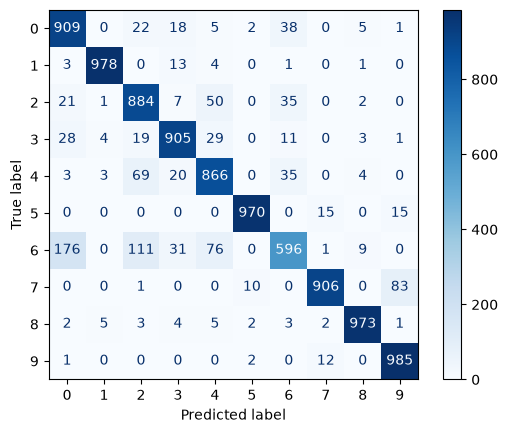

In [43]:
matrix_confusion=confusion_matrix(categorias_verdaderas, categorias_predichas)
disp = ConfusionMatrixDisplay(confusion_matrix=matrix_confusion)
disp.plot(cmap=plt.cm.Blues)
plt.show()

### Obtención de matriz de confusión normalizada

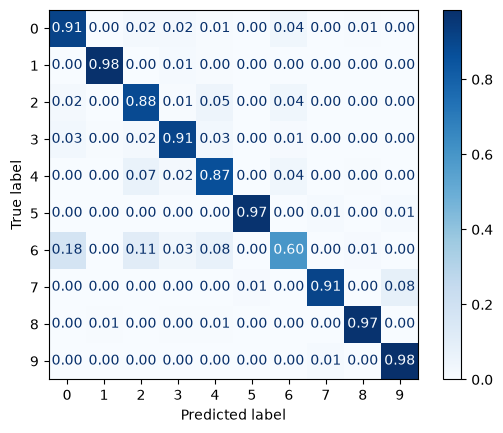

In [44]:
matrix_confusion=confusion_matrix(categorias_verdaderas, categorias_predichas, normalize='true')
disp = ConfusionMatrixDisplay(confusion_matrix=matrix_confusion)
disp.plot(cmap=plt.cm.Blues, values_format='.2f')
plt.show()

## Guardar modelo entrenado

Para guardar nuestro modelo entrenado, almacenamos en un archivo los pesos ajustados finales de la red neuronal.

In [50]:
torch.save(red_cnn.state_dict(), "/mnt/c/Users/vrahu/Documents/Ismadlsh/CCG/2026-S5/Data_Science/src/models/CNN_prediction_fashionist.mod")
print("Mejor modelo guardado!")

Mejor modelo guardado!


# Uso del modelo para inferencia


## Cargar mejor modelo entrenado desde archivo

Primero, creamos una instancia de la red neuronal y luego le pasamos los pesos almacenados.


In [51]:
mejor_modelo = CNN().to(device)
mejor_modelo.load_state_dict(torch.load("/mnt/c/Users/vrahu/Documents/Ismadlsh/CCG/2026-S5/Data_Science/src/models/CNN_prediction_fashionist.mod"))

<positron-console-cell-51>:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.


<All keys matched successfully>

## Usar mejor modelo entrenado


### Visualización de ejemplos del dataset de prueba

Id de categoría del ejemplo: 0 - categoría: Camiseta/top



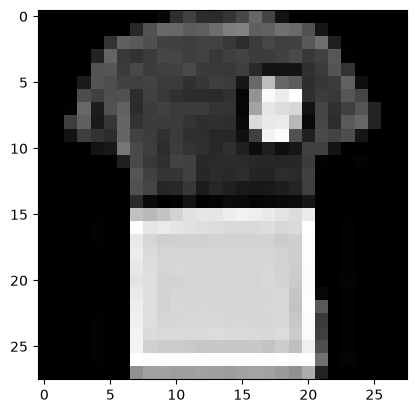

In [47]:
# Seleccionamos un ejemplo del dataset de prueba mediante un índice
numero_de_ejemplo = 120
imagen, id_categoria = dataset_test[numero_de_ejemplo]
# Imprimimos el id y la categoría del ejemplo
print('Id de categoría del ejemplo:', id_categoria, '- categoría:', ids_en_categorias[id_categoria])
print()
# Imprimimos la imagen del ejemplo
plt.imshow(imagen[0], cmap='gray')

### Predicción de un ejemplo con el mejo modelo entrenado

Usamos nuestro mejor modelo entrenado en modo de evaluación `model.eval()` y sin ajustes de pesos: `torch.no_grad()`.

Imprimimos la imagen de la predicción del modelo para compararla con la categoría verdadera.


Logits: tensor([[-38.9408, -26.1467,  -8.2066, -23.0609, -25.7546, -11.4756, -29.5994,
          21.9459, -10.9851,  -5.5540]], device='cuda:0')
-------------------------------
Índice logit máximo: 7 que corresponde a la categoría predicha: Zapato deportivo
-------------------------------
Id de categoría verdadera: 7 que corresponden a la categoría: Zapato deportivo
Imagen


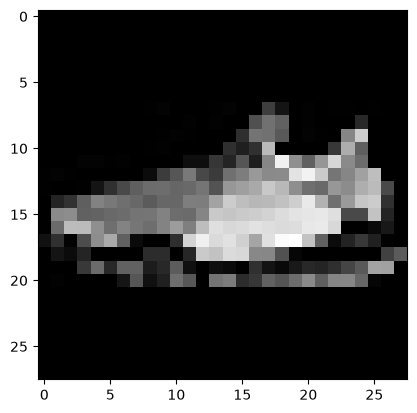

In [54]:
# Activamos nuestra red en modo de prueba
mejor_modelo.eval()
# Seleccionamos un ejemplo del dataset de prueba [x][y]:
# - x indica el número de instancia
# - y=[0] indica la imagen (canal, alto, ancho)
# - y=[1] indica la categoría
numero_de_ejemplo = 70
X, y = dataset_test[numero_de_ejemplo][0], dataset_test[numero_de_ejemplo][1]
imagen = X[0]
# Desactivamos los cálculos de gradientes porque no estamos en fase de entrenamiento
with torch.no_grad():
    # Enviamos ejemplo al device
    X = X.to(device)
    # Obtenemos predicciones de la red (logits) para la imagen del ejemplo
    logits = mejor_modelo(X)
    # Imprimimos los logits
    print("\nLogits:", logits)
    # Obtenemos índice correspondiente al valor máximo de los logits
    indice_logit_maximo = logits[0].argmax(0)
    # Obtenemos categoría predicha con el índice del valor máximo de los logits
    categoria_predicha = ids_en_categorias[indice_logit_maximo.item()]
    print("-------------------------------")
    print("Índice logit máximo:", indice_logit_maximo.item(), "que corresponde a la categoría predicha:", categoria_predicha)
    categoria_verdadera = y
    # Obtenemos categoría verdadera
    vestimenta = ids_en_categorias[categoria_verdadera]
    print("-------------------------------")
    print("Id de categoría verdadera:", categoria_verdadera, "que corresponden a la categoría:", vestimenta)
    print("Imagen")
    plt.imshow(imagen, cmap='gray')
